# Onde está o faturamento de 2025?

As 5.000 vendas de 2025, olhadas por região, mês e canal, para a diretoria comercial decidir onde concentrar esforço em 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [2]:
COR_PRIMARIA, COR_SECUNDARIA, COR_DESTAQUE = "#0072B2", "#94A3B8", "#E69F00"
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110, "font.size": 12,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

In [3]:
def reais(v):
    return f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

## Os dados foram lidos corretamente?

In [4]:
df = pd.read_csv("dados/vendas.csv", parse_dates=["data"])
df.shape

(5000, 8)

In [5]:
df.dtypes.to_frame("tipo")

,tipo
data,datetime64[us]
produto,str
categoria,str
regiao,str
quantidade,int64
preco_unitario,float64
custo_unitario,float64
canal_venda,str


In [6]:
df.head()

,data,produto,categoria,regiao,quantidade,preco_unitario,custo_unitario,canal_venda
0,2025-01-01,Mouse,Acessórios,Centro-Oeste,5,52.97,30.53,Online
1,2025-01-01,Monitor,Eletrônicos,Sul,7,1118.13,765.68,Loja física
2,2025-01-01,Tablet,Eletrônicos,Centro-Oeste,6,1611.59,959.28,Marketplace
3,2025-01-01,Monitor,Eletrônicos,Nordeste,4,953.18,559.37,Loja física
4,2025-01-01,Teclado,Acessórios,Sul,6,174.44,124.57,Online


**Leitura ok:** uma linha por venda, datas como data, quantidades e preços como número, acentos legíveis nos nomes.

## Os dados têm problemas?

In [7]:
faltando = df.isna().sum().to_frame("linhas")
faltando["%"] = (faltando["linhas"] / len(df) * 100).round(1)
faltando[faltando["linhas"] > 0]

,linhas,%
regiao,154,3.1


In [8]:
regras = {
    "quantidade zero ou negativa": df["quantidade"] <= 0,
    "preço zero ou negativo": df["preco_unitario"] <= 0,
    "vendido abaixo do custo": df["preco_unitario"] < df["custo_unitario"],
}
pd.DataFrame({"linhas": {regra: int(m.sum()) for regra, m in regras.items()}})

,linhas
quantidade zero ou negativa,0
preço zero ou negativo,0
vendido abaixo do custo,0


In [9]:
int(df.duplicated().sum())

0

**Resultado:** só a região falta, em 154 vendas (3,1%). Não há valores impossíveis nem linhas repetidas. **Decisão:** manter essas vendas, marcadas como "Não informada" — apagá-las tiraria quase 3% do faturamento dos totais.

In [10]:
df["regiao"] = df["regiao"].fillna("Não informada")
df["faturamento"] = df["quantidade"] * df["preco_unitario"]
df["lucro"] = df["quantidade"] * (df["preco_unitario"] - df["custo_unitario"])
df[["regiao", "faturamento", "lucro"]].head()

,regiao,faturamento,lucro
0,Centro-Oeste,264.85,112.20
1,Sul,7826.91,2467.15
2,Centro-Oeste,9669.54,3913.86
3,Nordeste,3812.72,1575.24
4,Sul,1046.64,299.22


In [11]:
df.to_parquet("saidas/dados_tratados.parquet")

## Qual região fatura mais?

In [12]:
#| relatorio: mostrar
por_regiao = df.groupby("regiao").agg(vendas=("faturamento", "size"), faturamento=("faturamento", "sum"))
por_regiao["% do total"] = (por_regiao["faturamento"] / por_regiao["faturamento"].sum() * 100).round(1)
por_regiao["por venda"] = (por_regiao["faturamento"] / por_regiao["vendas"]).round(0)
por_regiao.sort_values("faturamento", ascending=False).round(0)

,vendas,faturamento,% do total,por venda
regiao,,,,
Sudeste,1933,9827937.0,39.0,5084.0
Sul,875,4380944.0,18.0,5007.0
Nordeste,857,4140642.0,17.0,4832.0
Centro-Oeste,590,3086275.0,12.0,5231.0
Norte,591,2854712.0,11.0,4830.0
Não informada,154,725629.0,3.0,4712.0


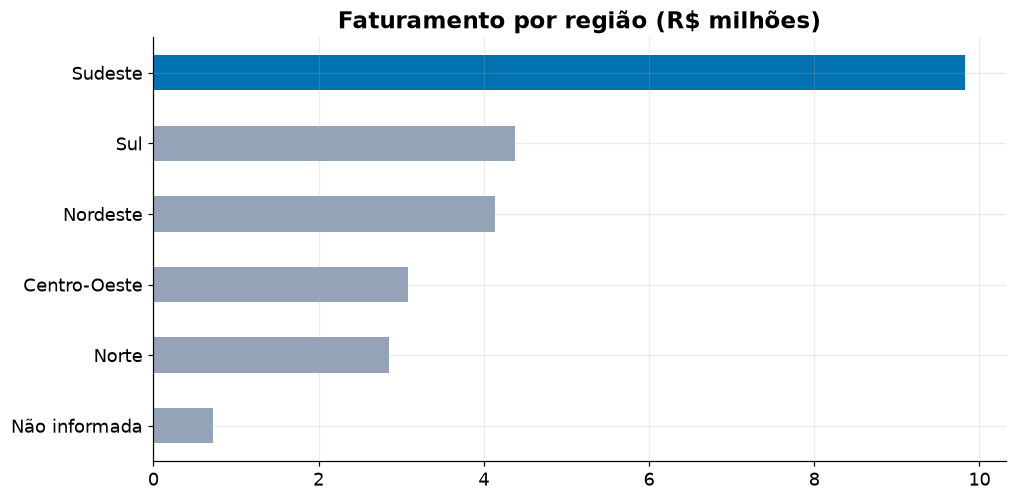

In [13]:
ordem = por_regiao["faturamento"].sort_values().div(1e6)
cores = [COR_PRIMARIA if r == "Sudeste" else COR_SECUNDARIA for r in ordem.index]
ax = ordem.plot.barh(color=cores)
ax.set_title("Faturamento por região (R$ milhões)")
ax.set_xlabel("")
ax.set_ylabel("");

**Resultado:** o Sudeste responde por cerca de 39% do faturamento — mas porque vende mais vezes, não porque cada venda vale mais: o valor por venda fica parecido em todas as regiões (entre `R$ 4,7 mil` e `R$ 5,2 mil`). É tamanho de mercado, não ticket.

## O faturamento muda ao longo do ano?

Os meses têm tamanhos diferentes, então a comparação é pelo faturamento **por dia**.

In [14]:
mensal = df.set_index("data").resample("MS")["faturamento"].sum().to_frame("faturamento")
mensal["por dia"] = mensal["faturamento"] / mensal.index.days_in_month
mensal["vendas"] = df.set_index("data").resample("MS").size()
mensal.round(0)

,faturamento,por dia,vendas
data,,,
2025-01-01,1108187.0,35748.0,243
2025-02-01,1341894.0,47925.0,249
2025-03-01,1740646.0,56150.0,362
2025-04-01,1715095.0,57170.0,335
2025-05-01,1896749.0,61185.0,393
2025-06-01,1681848.0,56062.0,358
2025-07-01,1991034.0,64227.0,383
2025-08-01,2073661.0,66892.0,435
2025-09-01,2108097.0,70270.0,411


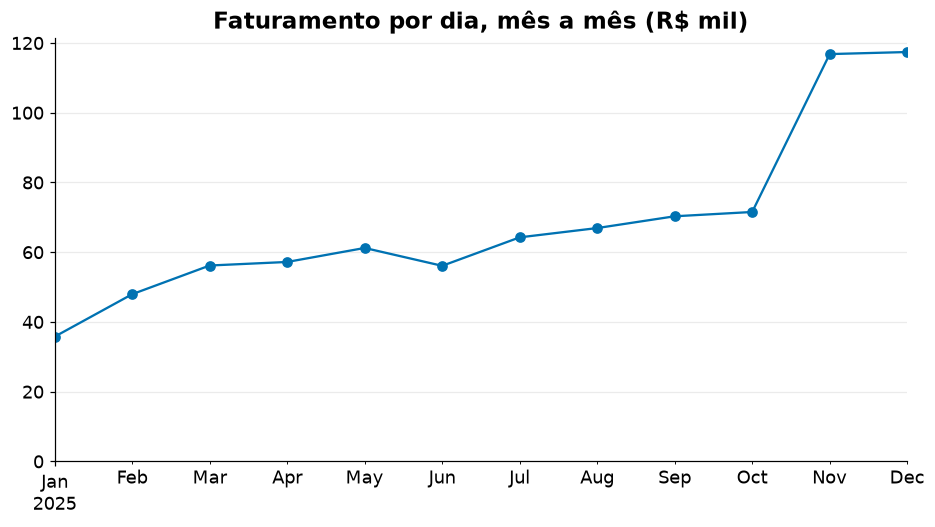

In [15]:
ax = mensal["por dia"].div(1e3).plot(marker="o", color=COR_PRIMARIA)
ax.set_title("Faturamento por dia, mês a mês (R$ mil)")
ax.set_xlabel("")
ax.set_ylim(0);

**Resultado:** o faturamento por dia sobe ao longo de 2025 e salta em novembro e dezembro — mais de 60% acima de outubro. Os dados cobrem só 2025, então não dá para dizer se é crescimento do negócio ou o movimento normal de fim de ano (Black Friday, Natal). Para separar os dois, seria preciso o mesmo período de 2024.

## Algum canal dá mais margem?

In [16]:
#| relatorio: mostrar
por_canal = df.groupby("canal_venda").agg(vendas=("lucro", "size"), faturamento=("faturamento", "sum"), lucro=("lucro", "sum"))
por_canal["margem %"] = (por_canal["lucro"] / por_canal["faturamento"] * 100).round(1)
por_canal[["vendas", "margem %"]]

,vendas,margem %
canal_venda,,
Loja física,1561,36.4
Marketplace,1226,36.2
Online,2213,36.4


**Resultado:** não. A margem fica em torno de 36% nos três canais, com mais de mil vendas em cada um. Nesta base, o canal muda o volume, não a rentabilidade de cada venda.

## Conclusão

- **Onde:** o Sudeste concentra cerca de 39% do faturamento por volume de vendas — o valor de cada venda é parecido em todas as regiões.
- **Quando:** novembro e dezembro faturam por dia mais de 60% acima de outubro. Sem os dados de 2024, não dá para separar fim de ano de crescimento.
- **Como:** a margem é a mesma nos três canais (cerca de 36%); escolher canal não muda a rentabilidade.
- **Próximo passo:** trazer as vendas de 2024 para medir se o pico de fim de ano se repete.